In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Importing Data

In [3]:
conn =sqlite3.connect('customer_churn.db')
sql_query=''' 
         SELECT name
         FROM sqlite_master
         WHERE type='table';
'''
tables=pd.read_sql(sql_query,conn)
# creating dataframe for each table
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * from {table_name}",conn)
    globals()[f'df_{table_name}']=df
    print(f'Created dataframe : df_{table_name}')

    df_db_customer: pd.DataFrame
    df_db_subscription: pd.DataFrame
    df_db_support: pd.DataFrame

conn.close()

Created dataframe : df_db_customer
Created dataframe : df_db_subscription
Created dataframe : df_db_support


# Data Cleaning

In [4]:
# Customer DataFrame

In [5]:
df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [6]:
# rename column name - name
df_db_customer.rename(columns={'name':'customer_name'})

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [7]:
# dropping column - interests and pincode
df_db_customer.drop(columns=['interests','pincode'],inplace=True)
df_db_customer

C:\Users\Samrat\AppData\Local\Temp\ipykernel_13664\2306848761.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_db_customer.drop(columns=['interests','pincode'],inplace=True)


,customerid,name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [8]:
# change datatype - dob
(df_db_customer['dob'])=pd.to_datetime(df_db_customer['dob'])

In [9]:
# Data standarization
df_db_customer['gender'].unique()
df_db_customer['gender']=df_db_customer['gender'].replace({'Men' : 'Male','Women' : 'Female'})

In [10]:
# fixing missing values - country
df_db_customer[df_db_customer['country'].isna()]
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [11]:
df_db_customer[df_db_customer['country'].isna()] # no null value in country col
df_db_customer

,customerid,name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,India,Delhi,Female,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,Nepal,Kathmandu,Female,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [12]:
# Subscription DataFrame

In [13]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [14]:
# changing datatype from string to datetime.
date_col=['subscription_start_date','renewal_date','cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [15]:
# Support DataFrame

In [16]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [17]:
# Dropping unwanted columns --> col_1 and comment.
df_db_support.drop(columns=['col_1','comment'],inplace=True)

C:\Users\Samrat\AppData\Local\Temp\ipykernel_13664\976124995.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_db_support.drop(columns=['col_1','comment'],inplace=True)


In [18]:
# Changing complaint_date datatype to datetime.
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


# Feature Engineering and Data Analysis

In [19]:
# create a new col using exesting col - churn flag
df_db_subscription['churn flag']=np.where(df_db_subscription['cancellation_date'].notna(),1,0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [20]:
# first fix support table duplicates then merge
df=(df_db_subscription
                .merge(df_db_customer , on= 'customerid',how='left')
                .merge(df_db_support , on= 'customerid' , how='left'))


In [21]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [22]:
# merge df
df=(df_db_subscription
                .merge(df_db_customer , on= 'customerid',how='left')
                .merge(df_db_support , on= 'customerid' , how='left'))

In [23]:
# exporting final data and making it csv file
df.to_csv('Exported_churn_data.csv',index=False)

### Data Analysis

In [24]:
# 1. churn rates
churn_rate=df['churn flag'].mean()*100
print('churn_rate =',round(churn_rate,2),'%')

churn_rate = 28.57 %


In [25]:
# 2. Retention rate
Retention_rate = 100-churn_rate
print('Retention_rate =',round(Retention_rate,2),'%')


Retention_rate = 71.43 %


In [26]:
# 3. Churn by plan_type
churn_by_plan=df.groupby("plan_type")['churn flag'].mean().mul(100).round(2).reset_index(name='churn_rate %')
print(churn_by_plan)

  plan_type  churn_rate %
0     Basic         60.00
1   Premium         14.29
2  Standard         22.22


In [27]:
# 4. ARPU - Average revenue per users
arpu = df['monthly_charges'].mean()
print('Average revenue per user =',round(arpu,2))

Average revenue per user = 18.85


In [28]:
# 5. calculate avg customer age
today_date=pd.Timestamp.today()
df['dob'] = pd.to_datetime(df['dob'])
age=today_date.year - df['dob'].dt.year
avg_age=age.mean()
print('Average customer age =',round(avg_age,2),'Years')


Average customer age = 36.9 Years


In [29]:
# 6. Avg Customer Tenure
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure))

Avg Tenure (Days) =  1577


In [30]:
# 7. Revenue at risk - revenue lost from churned users
revenue_at_risk=df.loc[df['churn flag'] == 1,'monthly_charges'].sum()
print('Revenue at risk ( Rs k ) =',revenue_at_risk)


Revenue at risk ( Rs k ) = 73.94


In [31]:
# 8. Esclation Rate
esclation_rate=(df['escalations']=='Y').mean()*100
print('Esclation Rate = ',round(esclation_rate,2),'%')

Esclation Rate =  19.05 %


In [32]:
# 9. Average complaint per user
avg_complaints=df['complaint_count'].sum() /df['customerid'].nunique()
print('Average complaints per user =',round(avg_complaints,2))

Average complaints per user = 0.43


In [33]:
# 10. Correlation Esclation vs churn
# df['escalations'] = np.where(df['escalations']== 'Y' ,1,0)  --> i.e encoding string to int type

df['escalations'] = np.where(df['escalations']== 'Y' ,1,0)

corr_df = df[['escalations','churn flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn flag'])
print('Correlation between escalation vs churn =',round(correlation,2))

Correlation between escalation vs churn = 0.77


In [34]:
# 11. Churn risk -- create a column using existing column
conditions=[
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]
choices = ['low','mid','high']
df['churn_risk']=np.select(conditions,choices,default='unknown')
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2062.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,India,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,1447.0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,India,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,2737.0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,419.0,high
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,India,Delhi,Female,1988-12-10,2025-03-18,0,90.0,1.0,1602.0,low
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,India,Meghalaya,Female,1976-09-21,2024-11-01,0,30.0,1.0,1142.0,high
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,India,Rajasthan,Male,1999-03-14,NaT,0,NaN,NaN,2457.0,low
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,Nepal,Kathmandu,Female,1985-07-07,NaT,0,NaN,NaN,1203.0,low
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,Nepal,Kathmandu,Male,1993-10-29,NaT,0,NaN,NaN,1678.0,low


# Data Visualization

### Using Matplotlib 

In [35]:
df_visual=df.copy()

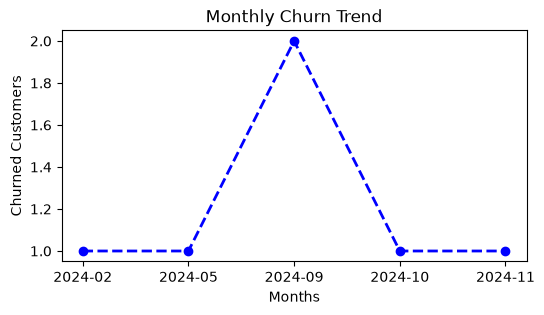

In [36]:
# 1. Monthly churn trend  -- (Time Series Kpi)
df_visual['cancellation_month']=df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn flag'] ==1].groupby('cancellation_month').size()

plt.figure(figsize=(6,3))

plt.plot(churn_trend.index.astype('str'), churn_trend.values , color ='blue' , marker='o' , linestyle ='dashed', linewidth= 2 , markersize= 6 )
plt.title("Monthly Churn Trend")
plt.xlabel('Months')
plt.ylabel('Churned Customers')
plt.show()

In [37]:
churn_plan = df_visual.groupby('plan_type')['churn flag'].mean()
churn_plan


plan_type
Basic       0.600000
Premium     0.142857
Standard    0.222222
Name: churn flag, dtype: float64

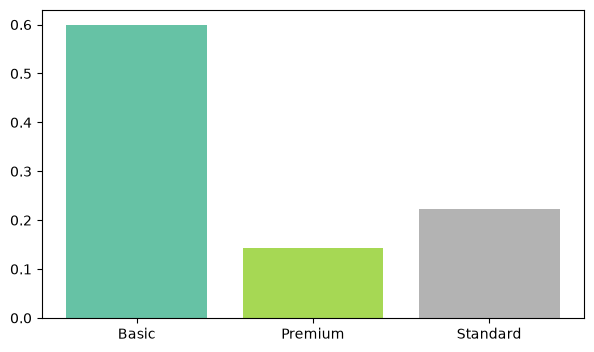

In [38]:
# 2. Churn by plan type
churn_plan = df_visual.groupby('plan_type')['churn flag'].mean()

colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(7,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

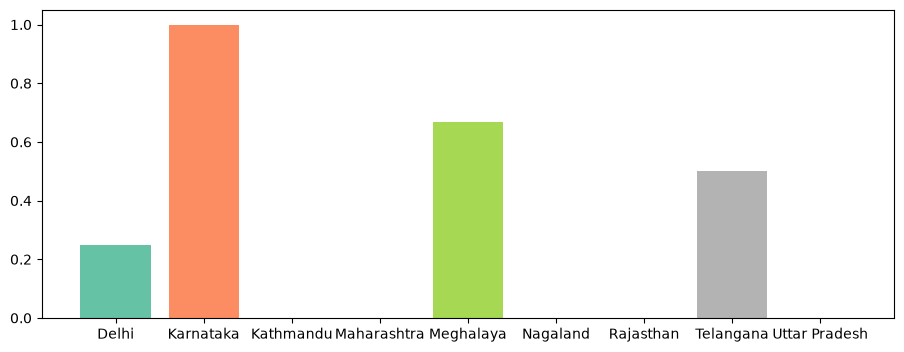

In [39]:
# 3. Churn by States
churn_plan = df_visual.groupby('state')['churn flag'].mean()

colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(11,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

### Using Seaborn

In [40]:
# encoding --> Convert str to numeric values 


df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn flag', 'churn_risk', 'escalations']]

order_mappings={
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk' : ['low', 'high', 'mid']
}
for col,order in order_mappings.items():
    df_encoded[col]=pd.Categorical(df_encoded[col].astype('category'), categories=order , ordered=True).codes

<Axes: >

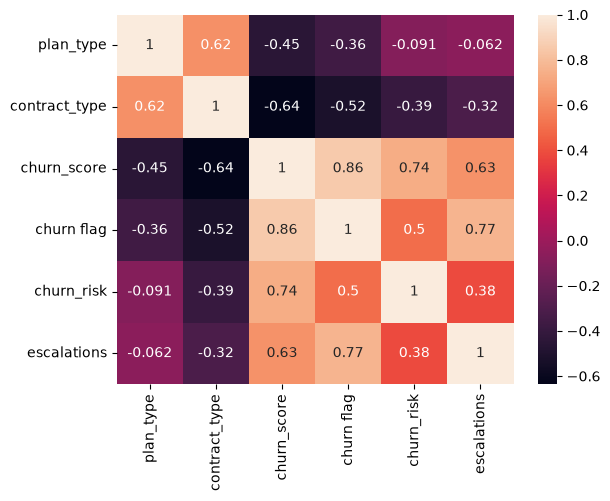

In [41]:
# 1. Heatmap
sns.heatmap(df_encoded.corr(), annot=True)

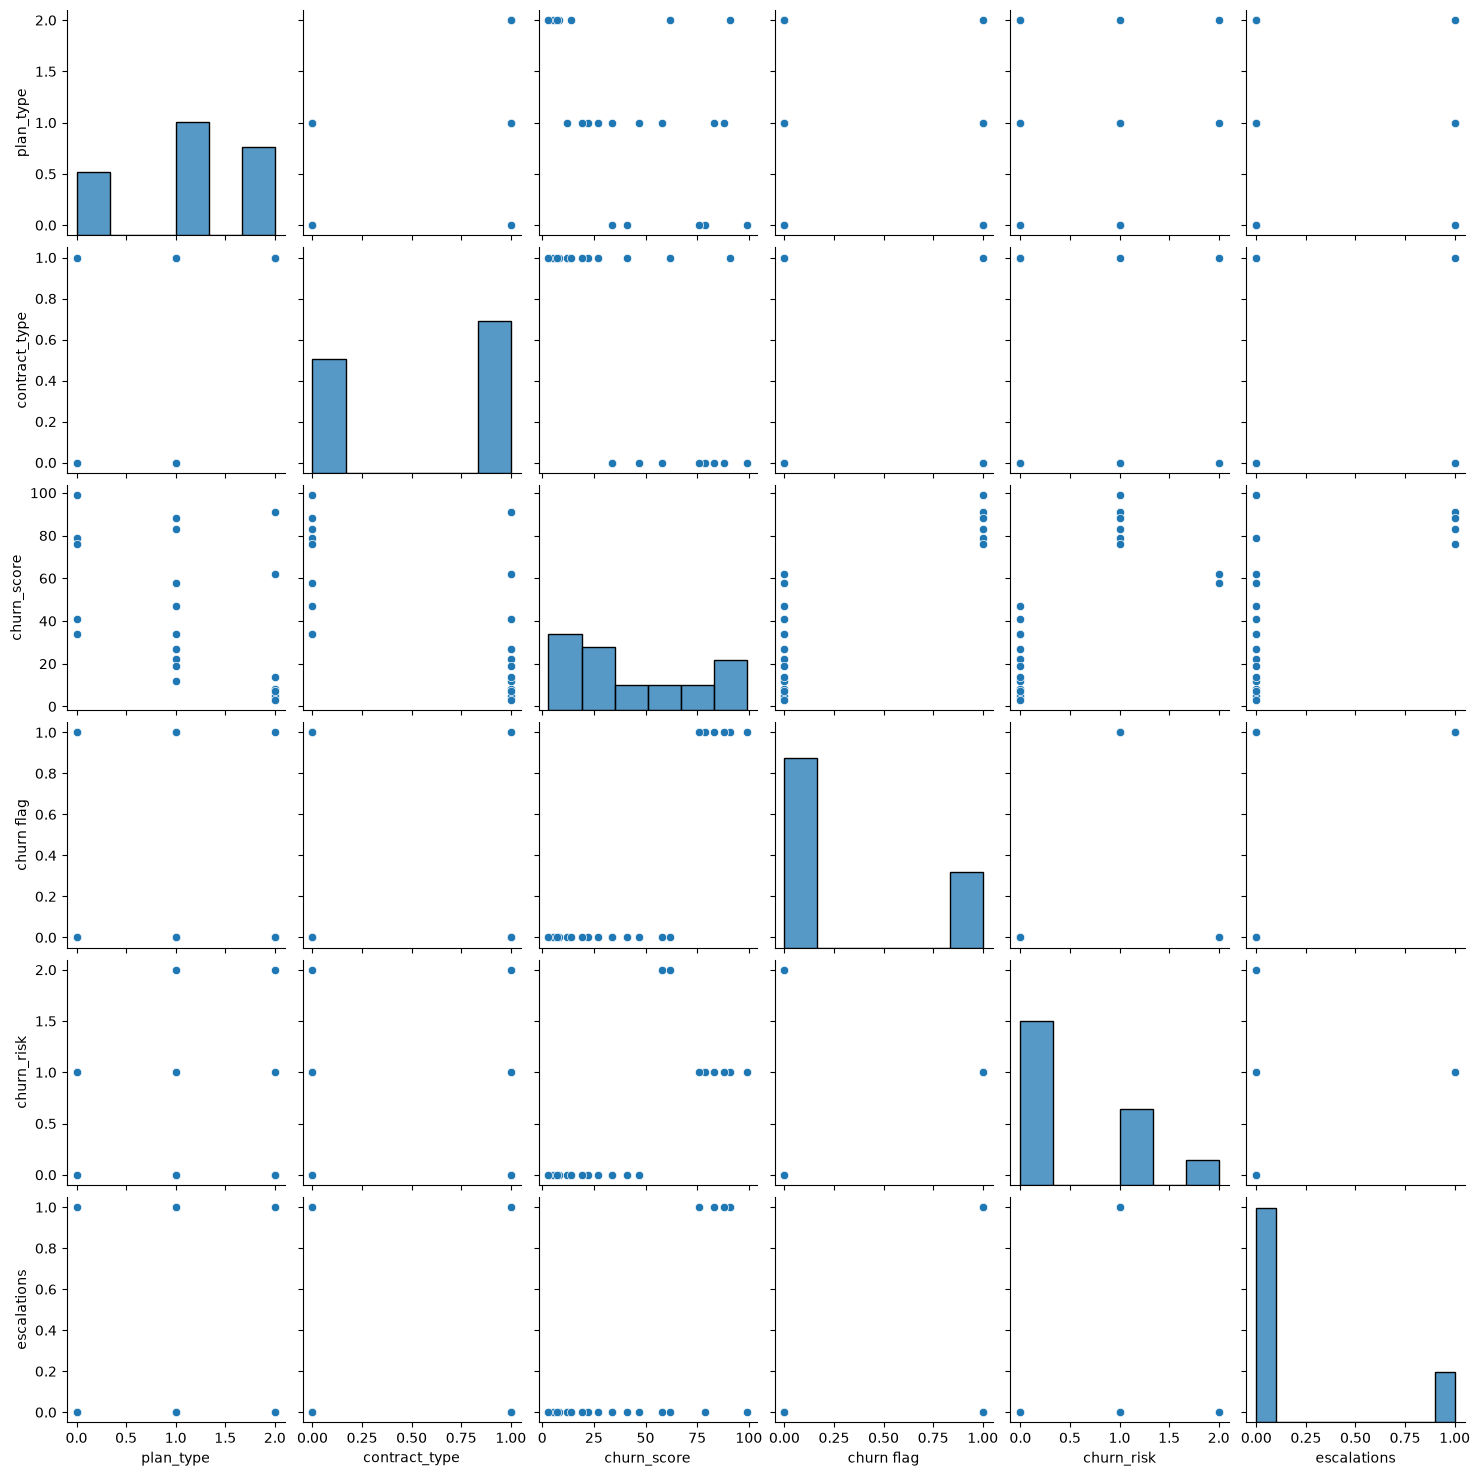

In [42]:
# 2. Pairplot  --> to find relationship in a dataset
sns.pairplot(df_encoded)

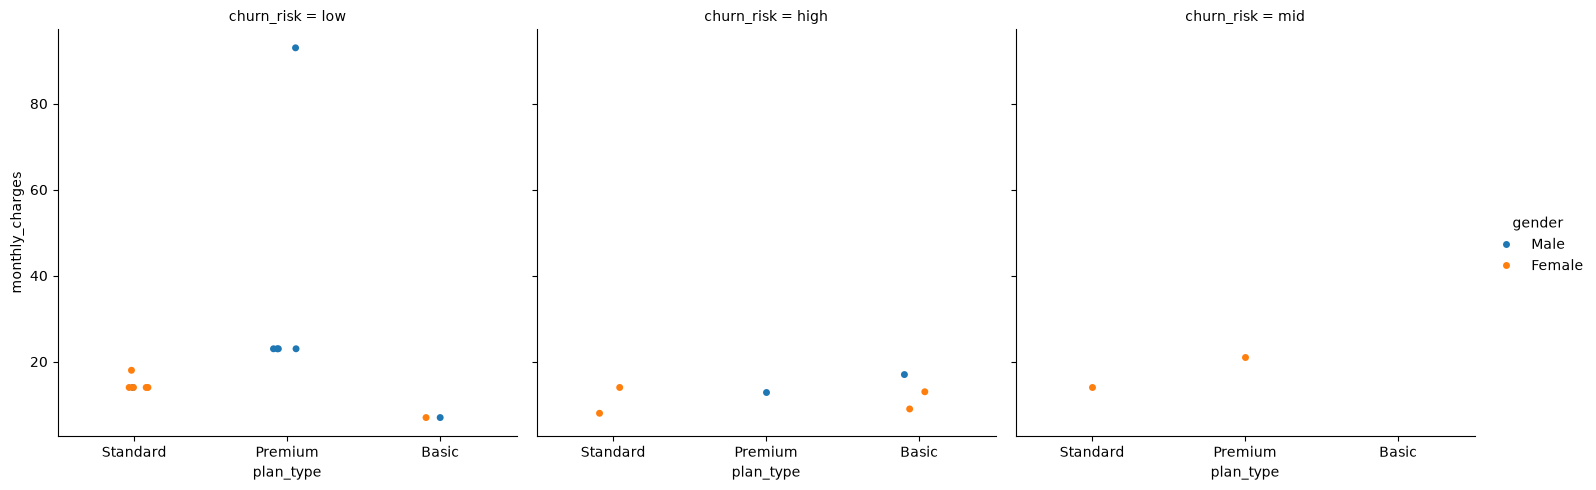

In [43]:
# 3. catplot / facegrid plot

sns.catplot(data=df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            col='churn_risk')


## Pivot Table

In [44]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn flag', 'name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [45]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn flag',
    aggfunc = 'mean'
)    

,churn flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [46]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn flag' : 'mean'
    }
)

,churn flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
